In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
from scipy.spatial.distance import cdist
np.random.seed(10)

c:\Users\msado\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
class softmax():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9

    def forward(self, x):
        x = x - np.max(x, axis=1, keepdims=True)
        exps = np.exp(x)
        self.out = exps / np.sum(exps, axis=1, keepdims=True)
        return self.out

    def backward(self, grad_output):
        return grad_output

class sigmoid():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9

    def forward(self, x):
        self.out = 1 / (1 + np.exp(-x))
        return self.out

    def backward(self, grad_output):
        # f'(x) = f(x) * (1 - f(x)) 
        return grad_output * self.out * (1 - self.out)
    
class relu():
    def __init__(self):
        self.input = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9

    def forward(self, x):
        self.input = x
        return np.maximum(0, x)
    
    def backward(self, grad_output):
        grad_input = grad_output.copy()
        grad_input[self.input <= 0] = 0
        return grad_input
    
class liniowa():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9

    def forward(self, x):
        self.out = x
        return self.out

    def backward(self, grad_output):
        return grad_output
    
class tanh():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9

    def forward(self, x):
        self.out = np.tanh(x)
        return self.out

    def backward(self, grad_output):
        # f'(x) = 1 - f(x)^2
        return grad_output * (1 - self.out ** 2)

In [3]:
class MSE:
    def __init__(self):
        self.cache_y_pred = None
        self.cache_y_true = None
        
    def forward(self, y_pred, y_true):
        self.cache_y_pred = y_pred
        self.cache_y_true = y_true
        return np.mean((y_pred - y_true) ** 2)
        
    def backward(self):
        return (self.cache_y_pred - self.cache_y_true)
    
class Crossentropy:
    def __init__(self):
        self.cache_y_pred = None
        self.cache_y_true = None
        
    def forward(self, y_pred, y_true):
        self.cache_y_pred = y_pred
        self.cache_y_true = y_true
        epsilon = 1e-15
        y_pred_clipped = np.clip(y_pred, epsilon, 1 - epsilon)
        strata = -np.sum(y_true * np.log(y_pred_clipped))
        return strata
        
    def backward(self):
        return (self.cache_y_pred - self.cache_y_true)

In [4]:
class warstwa_liniowa():
    def __init__(self, liczba_neuronow_wejsciowych, liczba_neuronow_wyjsciowych, inicjalizacja):
        self.liczba_neuronow_wejsciowych = liczba_neuronow_wejsciowych
        self.liczba_neuronow_wyjsciowych = liczba_neuronow_wyjsciowych

        self.wspolczynnik = 0.9

        # inicjalizacja wag za pomocą Xaviera
        if inicjalizacja == 'xavier':
            a = -np.sqrt(6/(liczba_neuronow_wejsciowych+liczba_neuronow_wyjsciowych))
            b = -a
        # inicjalizacja wag za pomocą He
        elif inicjalizacja == 'he':
            a = -np.sqrt(6/liczba_neuronow_wejsciowych)
            b = -a
        else:
            a = 0
            b = 1
        self.wagi = np.random.uniform(a, b, (liczba_neuronow_wejsciowych, liczba_neuronow_wyjsciowych))
        self.bias = np.zeros((1, liczba_neuronow_wyjsciowych))

        self.input = None
        self.grad_wagi = None
        self.grad_bias = None

        self.learning_rate = 0.01

        self.rmsprop_wagi = np.zeros_like(self.wagi)
        self.rmsprop_bias = np.zeros_like(self.bias)
        
        self.moment_wagi = np.zeros_like(self.wagi)
        self.moment_bias = np.zeros_like(self.bias)

    def forward(self, x):
        # x - neurony wejsciowe, wektor o dlugosci = liczba_neuronow_wejsciowych
        self.input = x
        return np.dot(x, self.wagi) + self.bias
    
    def backward(self, grad_output):
        # L - funkcja straty
        # grad_output = dL/dY
        # input = x
        
        N = len(self.input)

        # dL/dX
        grad_input = np.dot(grad_output, self.wagi.T)
        # dL/dW
        self.grad_wagi = np.dot(self.input.T, grad_output) / N
        # dL/db
        self.grad_bias = np.sum(grad_output, axis=0, keepdims=True) / N

        return grad_input
    
    def update(self):
        N = len(self.input)
        self.wagi -= self.learning_rate * self.grad_wagi
        self.bias -= self.learning_rate * self.grad_bias

    def update_moment(self):
        self.moment_wagi = self.wspolczynnik * self.moment_wagi + self.learning_rate * self.grad_wagi
        self.moment_bias = self.wspolczynnik * self.moment_bias + self.learning_rate * self.grad_bias
        self.wagi -= self.moment_wagi
        self.bias -= self.moment_bias

    def update_RMSProp(self):
        eps = 1e-8
        self.rmsprop_wagi = self.wspolczynnik * self.rmsprop_wagi + (1 - self.wspolczynnik) * (self.grad_wagi ** 2)
        self.rmsprop_bias = self.wspolczynnik * self.rmsprop_bias + (1 - self.wspolczynnik) * (self.grad_bias ** 2)
        self.wagi -= (self.learning_rate / np.sqrt(self.rmsprop_wagi + eps)) * self.grad_wagi
        self.bias -= (self.learning_rate / np.sqrt(self.rmsprop_bias + eps)) * self.grad_bias

In [5]:
class MLP():
    def __init__(self, warstwy, learning_rate, optymalizacja=None, wspolczynnik=0.9):
        self.warstwy = warstwy # lista obiektów warstwa_liniowa i funkcji aktywacji
        self.learning_rate = learning_rate
        self.optymalizacja = optymalizacja
        self.wspolczynnik = wspolczynnik
        for warstwa in self.warstwy:
            warstwa.learning_rate = self.learning_rate
            warstwa.wspolczynnik = self.wspolczynnik

    def forward(self, x):
        for warstwa in self.warstwy:
            x = warstwa.forward(x)
        return x
    
    def backward(self, grad_output):
        for warstwa in reversed(self.warstwy):
            grad_output = warstwa.backward(grad_output)
        return grad_output
    
    def update(self):
        for warstwa in self.warstwy:
            if self.optymalizacja == 'RMSProp' and hasattr(warstwa, 'update_RMSProp'):
                warstwa.update_RMSProp()
            elif self.optymalizacja == 'moment' and hasattr(warstwa, 'update_moment'):
                warstwa.update_moment()
            elif hasattr(warstwa, 'update'):
                warstwa.update()

In [6]:
def mse(y_true, y_pred):
    if y_true.ndim == 1 and y_pred.ndim == 2:
        liczba_klas = y_pred.shape[1]
        y_true_onehot = np.zeros_like(y_pred)
        y_true_onehot[np.arange(len(y_true)), y_true] = 1
        y_true_do_obliczen = y_true_onehot
    else:
        y_true_do_obliczen = y_true
        
    return np.mean((y_true_do_obliczen - y_pred) ** 2)

In [7]:
def f1(y_true, y_pred):
    if y_true.ndim == 2 and y_true.shape[1] > 1:
        y_true_labels = np.argmax(y_true, axis=1)
    else:
        y_true_labels = y_true.flatten()
        
    y_pred_labels = np.argmax(y_pred, axis=1)
    
    klasy = np.unique(y_true_labels)
    f1_suma = 0
    
    for k in klasy:
        TP = np.sum((y_pred_labels == k) & (y_true_labels == k))
        FP = np.sum((y_pred_labels == k) & (y_true_labels != k))
        FN = np.sum((y_pred_labels != k) & (y_true_labels == k))
        
        precision = TP / (TP + FP) if (TP + FP) > 0 else 0
        recall = TP / (TP + FN) if (TP + FN) > 0 else 0
        
        if precision + recall > 0:
            f1_k = 2 * (precision * recall) / (precision + recall)
        else:
            f1_k = 0
            
        f1_suma += f1_k
        
    return f1_suma / len(klasy)

In [8]:
def wykres_dopasowania_klasyfikacja(ax, X_dane, y_prawda, y_predykcja, tytul):
        margines = 0.1
        x_min, x_max = X_dane[:, 0].min() - margines, X_dane[:, 0].max() + margines
        y_min, y_max = X_dane[:, 1].min() - margines, X_dane[:, 1].max() + margines
        
        rozdzielczosc = 400
        xx, yy = np.meshgrid(np.linspace(x_min, x_max, rozdzielczosc),
                             np.linspace(y_min, y_max, rozdzielczosc))
        siatka = np.c_[xx.ravel(), yy.ravel()]
        
        # TŁO - prawdziwe wartości
        odleglosci = cdist(siatka, X_dane)
        najblizsze_idx = np.argmin(odleglosci, axis=1)
        
        Z_true = y_prawda[najblizsze_idx]
        Z_true = Z_true.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z_true, alpha=0.3, cmap='viridis')
        
        # KROPKI - przewidziane wartości przez model
        ax.scatter(X_dane[:, 0], X_dane[:, 1], c=y_predykcja, cmap='viridis', edgecolor='k', alpha=0.9, s=50)
        
        ax.set_title(tytul)
        ax.set_xlabel('Cecha X')
        ax.set_ylabel('Cecha Y')

In [9]:
def wykresy(X_train, y_train, X_test, y_test, y_pred_train, y_pred_test, hist_f1, hist_wagi, epoki, regresja=True, test=False):
    if (test):
        if regresja:
            # Wykres MSE
            plt.figure(figsize=(10, 4))
            plt.plot(range(epoki), hist_f1, color='red')
            plt.title('Wzrost MSE w kolejnych epokach')
            plt.xlabel('Epoka')
            plt.ylabel('MSE')
            plt.grid(True, linestyle='--', alpha=0.7)
            plt.show()
        else:
            # Wykres F1
            plt.figure(figsize=(10, 4))
            plt.plot(range(epoki), hist_f1, color='red')
            plt.title('Wzrost F1 w kolejnych epokach')
            plt.xlabel('Epoka')
            plt.ylabel('F1-score')
            plt.grid(True, linestyle='--', alpha=0.7)
            plt.show()

        if regresja:
            # Wykresy dopasowania regresja
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

            # Zbiór Treningowy
            ax1.scatter(X_train, y_train, color='blue', alpha=0.6, label='Prawdziwa wartość')
            ax1.scatter(X_train, y_pred_train, color='orange', alpha=0.6, label='Przewidziana wartość')
            ax1.set_title('Dopasowanie - Zbiór Treningowy')
            ax1.legend()

            # Zbiór Testowy
            ax2.scatter(X_test, y_test, color='blue', alpha=0.6, label='Prawdziwa wartość')
            ax2.scatter(X_test, y_pred_test, color='orange', alpha=0.6, label='Przewidziana wartość')
            ax2.set_title('Dopasowanie - Zbiór Testowy')
            ax2.legend()
            
        else:
            # Wykresy dopasowania klasyfikacja
            y_train_true = np.argmax(y_train, axis=1) if y_train.ndim > 1 else y_train
            y_train_pred = np.argmax(y_pred_train, axis=1) if y_pred_train.ndim > 1 else y_pred_train
            
            y_test_true = np.argmax(y_test, axis=1) if y_test.ndim > 1 else y_test
            y_test_pred = np.argmax(y_pred_test, axis=1) if y_pred_test.ndim > 1 else y_pred_test

            fig, axes = plt.subplots(1, 2, figsize=(14, 6))

            wykres_dopasowania_klasyfikacja(axes[0], X_train, y_train_true, y_train_pred, 'Trening (Tło: Wartości prawdziwe, Kropki: Wartości przewidziane)')
            wykres_dopasowania_klasyfikacja(axes[1], X_test, y_test_true, y_test_pred, 'Test (Tło: Wartości prawdziwe, Kropki: Wartości przewidziane)')

        plt.tight_layout()
        plt.show()

In [10]:
def train(X_train, y_train, X_test, y_test, model, epoki, rozmiar_batcha, funkcja_straty=MSE, regresja=True, test=False, test_score=False):
    # Skalowanie cech X
    x_min = X_train.min(axis=0)
    x_max = X_train.max(axis=0)

    X_train_scaled = (X_train - x_min) / (x_max - x_min)
    X_test_scaled = (X_test - x_min) / (x_max - x_min)

    # Skalowanie Y tylko jeśli to regresja
    if regresja:
        y_min = y_train.min(axis=0)
        y_max = y_train.max(axis=0)
        y_train_scaled = (y_train - y_min) / (y_max - y_min)
    else:
        y_train_scaled = y_train
    
    N = y_train.shape[0] 

    strata = funkcja_straty()

    hist_wagi = {i: [] for i, w in enumerate(model.warstwy) if hasattr(w, 'wagi')}
    hist_score = []

    for i in range(epoki):
        # Tasowanie danych
        indeksy = np.random.permutation(N)
        X_shuffled = X_train_scaled[indeksy]
        y_shuffled = y_train_scaled[indeksy]
        
        for start in range(0, N, rozmiar_batcha):
            koniec = start + rozmiar_batcha
            X_batch = X_shuffled[start:koniec]
            y_batch = y_shuffled[start:koniec]
            
            # Przejście w przód dla batcha
            y_pred_batch = model.forward(X_batch)
            
            # Strata i gradient
            loss = strata.forward(y_pred_batch, y_batch)
            grad_output = strata.backward() 
            
            # Wsteczna propagacja
            model.backward(grad_output)
            model.update()

        # Zapis historii wag co epokę
        for idx, warstwa in enumerate(model.warstwy):
            if hasattr(warstwa, 'wagi'):
                hist_wagi[idx].append(warstwa.wagi.copy())
        
        # Wyliczenie wyników co epokę
        y_pred_all = model.forward(X_train_scaled)

        if regresja:        
            y_pred_all_do_oceny = y_pred_all * (y_max - y_min) + y_min
            score_treningowe = mse(y_train, y_pred_all_do_oceny)
            nazwa_score = "MSE"
        else:
            y_pred_all_do_oceny = y_pred_all
            score_treningowe = f1(y_train, y_pred_all_do_oceny)
            nazwa_score = "F1"

        hist_score.append(score_treningowe)

        # Wyświetlanie logów co 100 epok
        if test and i % 100 == 0:
            if test_score:
                y_pred_test = model.forward(X_test_scaled)
                if regresja:
                    y_pred_test_unscaled = y_pred_test * (y_max - y_min) + y_min
                    score_testowe_krok = mse(y_test, y_pred_test_unscaled)
                else:
                    score_testowe_krok = f1(y_test, y_pred_test)
                print(f"Krok {i:>5} | {nazwa_score} Trening: {score_treningowe:>8.4f} | {nazwa_score} Test: {score_testowe_krok:>8.4f}")
            else:
                print(f"Krok {i:>5} | {nazwa_score} Trening: {score_treningowe:>8.4f}")

    if test:
        print("-" * 50)
        print(f"{nazwa_score} treningowe FINALNE: {hist_score[-1]:.4f}")

    y_pred_test_final = model.forward(X_test_scaled)
    if regresja:
        y_pred_test_final_do_oceny = y_pred_test_final * (y_max - y_min) + y_min
        score_test = mse(y_test, y_pred_test_final_do_oceny)
    else:
        y_pred_test_final_do_oceny = y_pred_test_final
        score_test = f1(y_test, y_pred_test_final_do_oceny)
        
    print(f"{nazwa_score} testowe FINALNE: {score_test:.4f}")

    # Rysowanie wykresów
    wykresy(X_train, y_train, X_test, y_test, y_pred_all_do_oceny, y_pred_test_final_do_oceny, hist_score, hist_wagi, epoki, regresja, test)

    return hist_score, score_test

In [11]:
def train_N_architektury(X_train, y_train, X_test, y_test, N=3, epoki=2000, rozmiar_batcha=64, regresja=False):
    wyniki = []
    
    aktywacje = {
        'Sigmoid': sigmoid,
        'Liniowa': liniowa,
        'ReLU': relu,
        'Tanh': tanh
    }
    
    architektury = {
        '1 warstwa': [10],
        '2 warstwy': [10, 10],
        '3 warstwy': [10, 10, 10]
    }
    
    wejscia = X_train.shape[1]
    wyjscia = y_train.shape[1] if y_train.ndim > 1 else 1
    
    x_min = X_train.min(axis=0)
    x_max = X_train.max(axis=0)
    X_train_scaled = (X_train - x_min) / (x_max - x_min)
    X_test_scaled = (X_test - x_min) / (x_max - x_min)

    for nazwa_akt, klasa_akt in aktywacje.items():
        for nazwa_arch, neurony_ukryte in architektury.items():
            print(f"\nRozpoczynam cykl: {nazwa_akt} + {nazwa_arch}")
            
            for n in range(N):
                warstwy_modelu = []
                in_f = wejscia
                
                for out_f in neurony_ukryte:
                    warstwy_modelu.append(warstwa_liniowa(in_f, out_f, 'xavier'))
                    warstwy_modelu.append(klasa_akt())
                    in_f = out_f
                
                warstwy_modelu.append(warstwa_liniowa(in_f, wyjscia, 'xavier'))
                if regresja:
                    pass
                else:
                    warstwy_modelu.append(softmax())
                
                model = MLP(tuple(warstwy_modelu), learning_rate=0.1, optymalizacja='moment')
                
                funkcja_straty = MSE if regresja else Crossentropy
                
                train(X_train, y_train, X_test, y_test, model, epoki=epoki, 
                      rozmiar_batcha=rozmiar_batcha, funkcja_straty=funkcja_straty, 
                      regresja=regresja, test=False)
                
                y_pred_train = model.forward(X_train_scaled)
                y_pred_test = model.forward(X_test_scaled)
                
                if regresja:
                    y_min, y_max = y_train.min(axis=0), y_train.max(axis=0)
                    score_train = mse(y_train, y_pred_train * (y_max - y_min) + y_min)
                    score_test = mse(y_test, y_pred_test * (y_max - y_min) + y_min)
                else:
                    score_train = f1(y_train, y_pred_train)
                    score_test = f1(y_test, y_pred_test)
                
                wyniki.append({
                    'Aktywacja': nazwa_akt,
                    'Architektura': nazwa_arch,
                    'Score_Trening': score_train,
                    'Score_Test': score_test
                })

    display(pd.DataFrame(wyniki))            
    return pd.DataFrame(wyniki)

In [12]:
def tabela_podsumowujaca(df):
    tabela_trening = df.groupby(['Aktywacja', 'Architektura'])['Score_Trening'].agg(['mean', 'std']).unstack()
    tabela_test = df.groupby(['Aktywacja', 'Architektura'])['Score_Test'].agg(['mean', 'std']).unstack()

    tabela_trening = tabela_trening.swaplevel(axis=1).sort_index(axis=1).round(3)
    tabela_test = tabela_test.swaplevel(axis=1).sort_index(axis=1).round(3)

    print("=== ZBIÓR TRENINGOWY ===")
    display(tabela_trening)
    
    print("\n=== ZBIÓR TESTOWY ===")
    display(tabela_test)

In [13]:
def rysuj_boxploty_architektury(df, nazwa_zbioru, metryka='F1-Score'):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # BOXPLOT 1: Wyniki Treningowe
    sns.boxplot(data=df, x='Aktywacja', y='Score_Trening', hue='Architektura', ax=axes[0])
    axes[0].set_title(f'{nazwa_zbioru} - {metryka} (Zbiór Treningowy)', fontsize=14, fontweight='bold')
    axes[0].set_ylabel(f'Wynik {metryka}', fontsize=12)
    axes[0].set_xlabel('Funkcja Aktywacji', fontsize=12)
    axes[0].grid(axis='y', linestyle='--', alpha=0.7)
    
    # BOXPLOT 2: Wyniki Testowe
    sns.boxplot(data=df, x='Aktywacja', y='Score_Test', hue='Architektura', ax=axes[1])
    axes[1].set_title(f'{nazwa_zbioru} - {metryka} (Zbiór Testowy)', fontsize=14, fontweight='bold')
    axes[1].set_ylabel(f'Wynik {metryka}', fontsize=12)
    axes[1].set_xlabel('Funkcja Aktywacji', fontsize=12)
    axes[1].grid(axis='y', linestyle='--', alpha=0.7)
    
    if metryka == 'F1-Score':
        axes[0].legend(loc='lower right', title='Architektura')
        axes[1].legend(loc='lower right', title='Architektura')
    else:
        axes[0].legend(loc='upper right', title='Architektura')
        axes[1].legend(loc='upper right', title='Architektura')
    
    plt.tight_layout()
    plt.show()

In [14]:
def wykres_score(zbior, score, hist_sigmoid=None, hist_line=None, hist_relu=None, hist_tanh=None, warstwa=1):
    plt.figure(figsize=(10, 5))

    if hist_sigmoid is not None:
        plt.plot(hist_sigmoid, label='Sigmoid', color='#ff6b6b', linewidth=2)
        
    if hist_line is not None:
        plt.plot(hist_line, label='Liniowa', color='#4ecdc4', linewidth=2)
        
    if hist_relu is not None:
        plt.plot(hist_relu, label='ReLU', color="#17bd61", linewidth=2)
        
    if hist_tanh is not None:
        plt.plot(hist_tanh, label='Tanh', color="#faee04", linewidth=2)

    plt.title(f'Porównanie zbieżności różnych funkcji aktywacji ({zbior}) - {warstwa} warstwa(y)', fontsize=14)
    plt.xlabel('Epoka', fontsize=12)
    
    plt.ylabel(score, fontsize=12) 

    plt.legend(fontsize=12, loc='lower right')
    plt.grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

In [15]:
def wykres_warstwy_funkcja(ax, hist_1, hist_2, hist_3, score, funkcja):
    if hist_1 is not None:
        ax.plot(hist_1, label='1 warstwa ukryta', color='#ff6b6b', linewidth=2)
    if hist_2 is not None:
        ax.plot(hist_2, label='2 warstwy ukryte', color='#4ecdc4', linewidth=2)
    if hist_3 is not None:
        ax.plot(hist_3, label='3 warstwy ukryte', color="#17bd61", linewidth=2)

    ax.set_title(f'Funkcja {funkcja}', fontsize=14)
    ax.set_xlabel('Epoka', fontsize=12)
    ax.set_ylabel(score, fontsize=12)

    ax.legend(fontsize=11, loc='upper right')
    ax.grid(True, linestyle='--', alpha=0.7)

In [16]:
def wykresy_warstwy(dane_historii, zbior, score):
    dostepne_funkcje = [f for f in ['Sigmoid', 'Liniowa', 'ReLU', 'Tanh'] if f in dane_historii]
    liczba_wykresow = len(dostepne_funkcje)
    
    if liczba_wykresow == 0:
        print("Brak danych do narysowania.")
        return

    if liczba_wykresow == 1:
        fig, axes = plt.subplots(1, 1, figsize=(8, 5))
        axes = [axes]
    elif liczba_wykresow == 2:
        fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    else:
        fig, axes = plt.subplots(2, 2, figsize=(15, 10))
        axes = axes.flatten()

    fig.suptitle(f'Porównanie zbieżności architektur dla różnych aktywacji ({zbior})', fontsize=16, fontweight='bold')

    for i, funkcja in enumerate(dostepne_funkcje):
        hist_1, hist_2, hist_3 = dane_historii[funkcja]
        wykres_warstwy_funkcja(axes[i], hist_1, hist_2, hist_3, score, funkcja)

    if liczba_wykresow > 1:
        for j in range(i + 1, len(axes)):
            fig.delaxes(axes[j])

    plt.tight_layout()
    plt.subplots_adjust(top=0.92 if liczba_wykresow > 2 else 0.85) 
    plt.show()

In [17]:
def porownanie_scatter(dane_wynikow, zbior="Zbiór Testowy"):
    plt.figure(figsize=(12, 8))
    
    kolory_funkcji = {
        'Sigmoid': '#ff6b6b',
        'Liniowa': '#4ecdc4',
        'ReLU': '#17bd61',
        'Tanh': '#faee04'
    }
    
    markery_warstw = {
        1: 'o',
        2: 's',
        3: '^'
    }
    
    neurony_x = [5, 10, 20]
    
    for funkcja, kolor in kolory_funkcji.items():
        if funkcja not in dane_wynikow:
            continue
            
        for warstwy, marker in markery_warstw.items():
            if warstwy not in dane_wynikow[funkcja]:
                continue
                
            dane_warstwy = dane_wynikow[funkcja][warstwy]
            
            valid_x = []
            valid_y = []
            for n in neurony_x:
                if n in dane_warstwy and dane_warstwy[n] is not None:
                    valid_x.append(n)
                    valid_y.append(dane_warstwy[n])
            
            if valid_x:
                plt.scatter(valid_x, valid_y, 
                            color=kolor, marker=marker, 
                            s=150, edgecolor='black', alpha=0.8, zorder=3)

    legenda_funkcji = [Line2D([0], [0], marker='o', color='w', 
                              markerfacecolor=k, markersize=12, label=f) 
                       for f, k in kolory_funkcji.items()]
                      
    legenda_warstw = [Line2D([0], [0], marker=m, color='w', 
                             markeredgecolor='black', markerfacecolor='gray', 
                             markersize=12, label=f'{w} warstwa(y)') 
                      for w, m in markery_warstw.items()]
                       
    leg1 = plt.legend(handles=legenda_funkcji, title="Aktywacja (Kolor)", 
                      loc='upper left', bbox_to_anchor=(1.02, 1), 
                      fontsize=11, title_fontsize=12)
    
    plt.gca().add_artist(leg1) 
    
    plt.legend(handles=legenda_warstw, title="Liczba warstw (Kształt)", 
               loc='upper left', bbox_to_anchor=(1.02, 0.72), 
               fontsize=11, title_fontsize=12)

    plt.title(f'Zestawienie MSE dla architektur sieci ({zbior})', fontsize=16, fontweight='bold')
    plt.xlabel('Liczba neuronów w warstwach ukrytych', fontsize=12)
    plt.ylabel('Finalne MSE Testowe', fontsize=12)
    
    plt.xticks(neurony_x)
    plt.grid(True, linestyle='--', alpha=0.5, zorder=0)
    
    plt.tight_layout()
    plt.subplots_adjust(right=0.75) 
    plt.show()

In [18]:
def to_one_hot(y, liczba_klas):
    m = np.zeros((len(y), liczba_klas))
    m[np.arange(len(y)), y.flatten()] = 1
    return m

# Dane multimodal-large

In [19]:
multimodal_large_test = pd.read_csv("mio1/regression/multimodal-large-test.csv")
multimodal_large_train = pd.read_csv("mio1/regression/multimodal-large-training.csv")
X_train = multimodal_large_train[['x']].to_numpy()
y_train = multimodal_large_train[['y']].to_numpy()
X_test = multimodal_large_test[['x']].to_numpy()
y_test = multimodal_large_test[['y']].to_numpy()

In [20]:
df_wyniki = train_N_architektury(X_train, y_train, X_test, y_test, 
                                       N=3, epoki=2000, rozmiar_batcha=64, regresja=True)


Rozpoczynam cykl: Sigmoid + 1 warstwa
MSE testowe FINALNE: 503.4240
MSE testowe FINALNE: 446.5236
MSE testowe FINALNE: 436.5476

Rozpoczynam cykl: Sigmoid + 2 warstwy
MSE testowe FINALNE: 75.7574
MSE testowe FINALNE: 71.4999
MSE testowe FINALNE: 244.1513

Rozpoczynam cykl: Sigmoid + 3 warstwy
MSE testowe FINALNE: 12.1643
MSE testowe FINALNE: 102.5534
MSE testowe FINALNE: 34.9601

Rozpoczynam cykl: Liniowa + 1 warstwa
MSE testowe FINALNE: 4446.8561
MSE testowe FINALNE: 4472.3321
MSE testowe FINALNE: 4446.3590

Rozpoczynam cykl: Liniowa + 2 warstwy
MSE testowe FINALNE: 4459.3870
MSE testowe FINALNE: 4722.9457
MSE testowe FINALNE: 4439.6195

Rozpoczynam cykl: Liniowa + 3 warstwy
MSE testowe FINALNE: 4437.9227
MSE testowe FINALNE: 4480.1693
MSE testowe FINALNE: 4447.7100

Rozpoczynam cykl: ReLU + 1 warstwa
MSE testowe FINALNE: 3267.1644
MSE testowe FINALNE: 3310.6221
MSE testowe FINALNE: 2798.4155

Rozpoczynam cykl: ReLU + 2 warstwy
MSE testowe FINALNE: 209.7169
MSE testowe FINALNE: 1298.

,Aktywacja,Architektura,Score_Trening,Score_Test
0,Sigmoid,1 warstwa,505.782816,503.424023
1,Sigmoid,1 warstwa,453.418866,446.523643
2,Sigmoid,1 warstwa,442.273223,436.547614
3,Sigmoid,2 warstwy,79.470576,75.757438
4,Sigmoid,2 warstwy,77.081314,71.499906
5,Sigmoid,2 warstwy,235.962128,244.151267
6,Sigmoid,3 warstwy,15.460074,12.164307
7,Sigmoid,3 warstwy,100.080907,102.553420
8,Sigmoid,3 warstwy,38.707646,34.960114
9,Liniowa,1 warstwa,4412.382632,4446.856147


In [21]:
tabela_podsumowujaca(df_wyniki)

=== ZBIÓR TRENINGOWY ===


Architektura 1 warstwa          2 warstwy          3 warstwy         
                  mean      std      mean      std      mean      std
Aktywacja                                                            
Liniowa       4422.622   16.532  4501.148  151.242  4419.175   21.948
ReLU          3082.432  265.994   982.917  669.115    70.469  100.242
Sigmoid        467.158   33.911   130.838   91.048    51.416   43.718
Tanh           254.662   26.321     8.899    0.062     6.101    0.225


=== ZBIÓR TESTOWY ===


Architektura 1 warstwa          2 warstwy          3 warstwy         
                  mean      std      mean      std      mean      std
Aktywacja                                                            
Liniowa       4455.182   14.854  4540.651  158.181  4455.267   22.114
ReLU          3125.401  284.010  1007.498  699.269    68.903  102.099
Sigmoid        462.165   36.078   130.470   98.474    49.893   47.008
Tanh           265.199   25.333     4.961    0.774     2.302    0.448

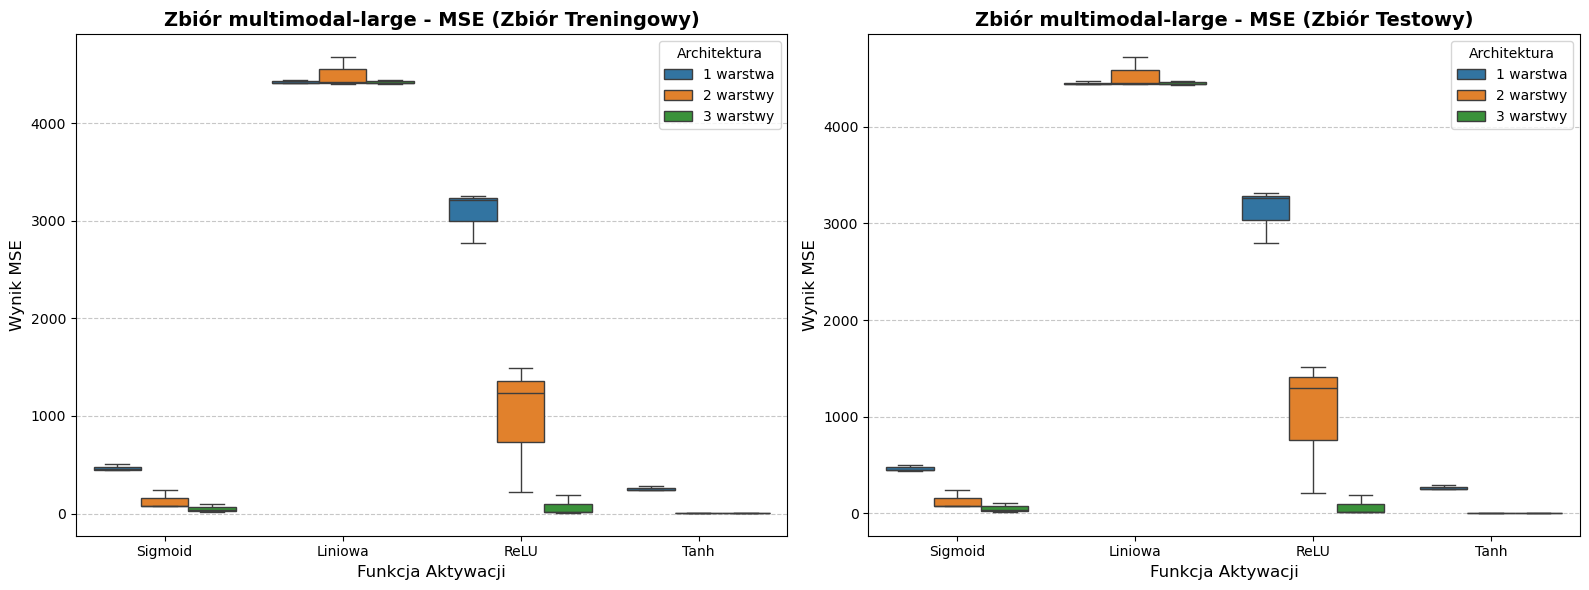

In [22]:
rysuj_boxploty_architektury(df_wyniki, nazwa_zbioru="Zbiór multimodal-large", metryka="MSE")

# Dane steps-large

In [23]:
steps_large_test = pd.read_csv("mio1/regression/steps-large-test.csv")
steps_large_train = pd.read_csv("mio1/regression/steps-large-training.csv")
X_train = steps_large_train[['x']].to_numpy()
y_train = steps_large_train[['y']].to_numpy()
X_test = steps_large_test[['x']].to_numpy()
y_test = steps_large_test[['y']].to_numpy()

In [24]:
df_wyniki = train_N_architektury(X_train, y_train, X_test, y_test, 
                                       N=3, epoki=6000, rozmiar_batcha=64, regresja=True)


Rozpoczynam cykl: Sigmoid + 1 warstwa
MSE testowe FINALNE: 427.9017
MSE testowe FINALNE: 421.8549
MSE testowe FINALNE: 450.9754

Rozpoczynam cykl: Sigmoid + 2 warstwy
MSE testowe FINALNE: 95.3510
MSE testowe FINALNE: 109.6565
MSE testowe FINALNE: 126.7493

Rozpoczynam cykl: Sigmoid + 3 warstwy
MSE testowe FINALNE: 42.6490
MSE testowe FINALNE: 47.2414
MSE testowe FINALNE: 46.9451

Rozpoczynam cykl: Liniowa + 1 warstwa
MSE testowe FINALNE: 531.5286
MSE testowe FINALNE: 528.9024
MSE testowe FINALNE: 531.6600

Rozpoczynam cykl: Liniowa + 2 warstwy
MSE testowe FINALNE: 529.1506
MSE testowe FINALNE: 530.9227
MSE testowe FINALNE: 536.8631

Rozpoczynam cykl: Liniowa + 3 warstwy
MSE testowe FINALNE: 534.5133
MSE testowe FINALNE: 530.7939
MSE testowe FINALNE: 543.4561

Rozpoczynam cykl: ReLU + 1 warstwa
MSE testowe FINALNE: 407.5350
MSE testowe FINALNE: 460.5726
MSE testowe FINALNE: 460.2056

Rozpoczynam cykl: ReLU + 2 warstwy
MSE testowe FINALNE: 294.4477
MSE testowe FINALNE: 452.1369
MSE test

,Aktywacja,Architektura,Score_Trening,Score_Test
0,Sigmoid,1 warstwa,423.496439,427.901706
1,Sigmoid,1 warstwa,419.633766,421.854945
2,Sigmoid,1 warstwa,444.693495,450.975401
3,Sigmoid,2 warstwy,96.015082,95.351018
4,Sigmoid,2 warstwy,110.494226,109.656514
5,Sigmoid,2 warstwy,134.590268,126.749341
6,Sigmoid,3 warstwy,46.290763,42.649028
7,Sigmoid,3 warstwy,52.334020,47.241424
8,Sigmoid,3 warstwy,49.133941,46.945056
9,Liniowa,1 warstwa,519.806312,531.528553


In [25]:
tabela_podsumowujaca(df_wyniki)

=== ZBIÓR TRENINGOWY ===


Architektura 1 warstwa         2 warstwy          3 warstwy         
                  mean     std      mean      std      mean      std
Aktywacja                                                           
Liniowa        519.519   0.572   521.099    2.648   526.716    9.486
ReLU           437.628  26.744   286.855  168.375   165.690  251.418
Sigmoid        429.275  13.492   113.700   19.486    49.253    3.023
Tanh           163.526   7.194    24.658    1.777    15.391    4.435


=== ZBIÓR TESTOWY ===


Architektura 1 warstwa         2 warstwy          3 warstwy         
                  mean     std      mean      std      mean      std
Aktywacja                                                           
Liniowa        530.697   1.556   532.312    4.040   536.254    6.508
ReLU           442.771  30.516   289.882  164.585   166.880  260.513
Sigmoid        433.577  15.367   110.586   15.720    45.612    2.570
Tanh           156.677   5.922    21.121    1.392    14.960    4.209

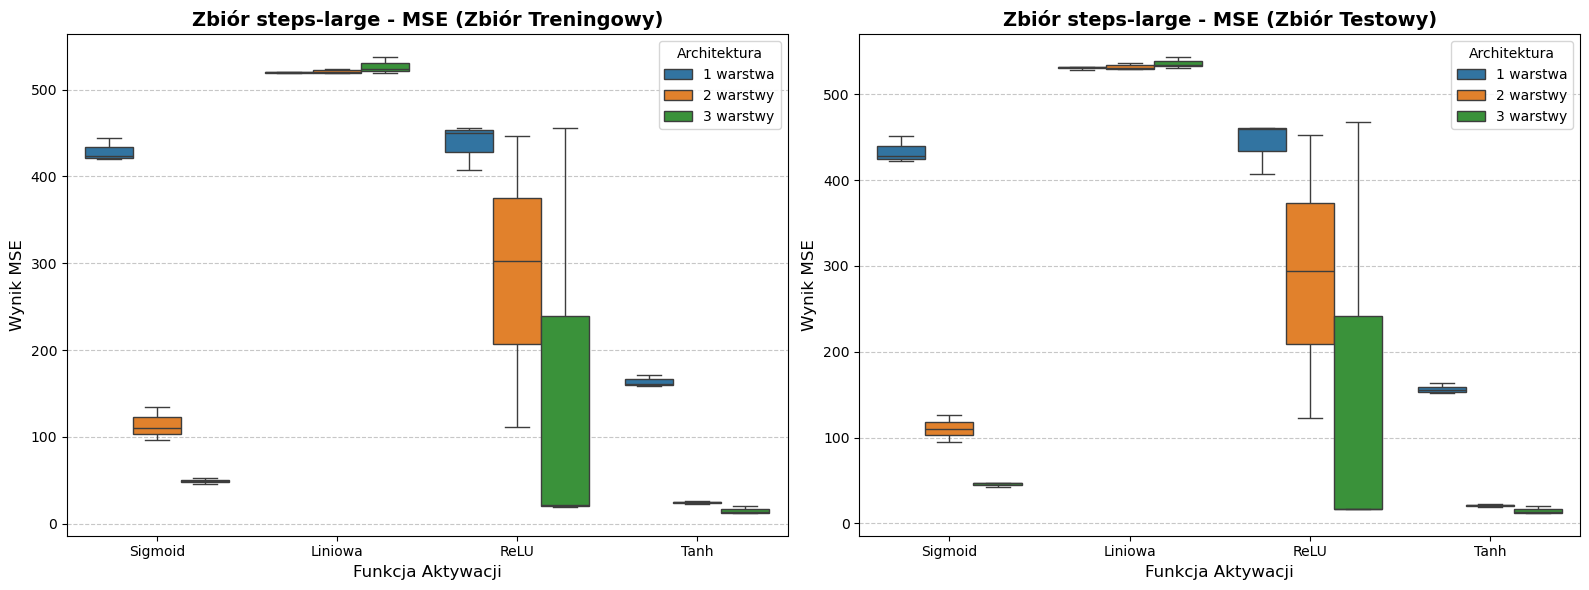

In [26]:
rysuj_boxploty_architektury(df_wyniki, nazwa_zbioru="Zbiór steps-large", metryka="MSE")

# Dane rings5-regular

In [27]:
rings5_regular_test = pd.read_csv("mio1/classification/rings5-regular-test.csv")
rings5_regular_train = pd.read_csv("mio1/classification/rings5-regular-training.csv")

X_train = rings5_regular_train[['x', 'y']].to_numpy() 
y_train_etykiety = rings5_regular_train[['c']].to_numpy().astype(int) 
X_test = rings5_regular_test[['x', 'y']].to_numpy()
y_test_etykiety = rings5_regular_test[['c']].to_numpy().astype(int)

liczba_klas = len(np.unique(y_train_etykiety))
y_train = to_one_hot(y_train_etykiety, liczba_klas)
y_test = to_one_hot(y_test_etykiety, liczba_klas)

In [28]:
df_wyniki = train_N_architektury(X_train, y_train, X_test, y_test, 
                                       N=3, epoki=2000, rozmiar_batcha=64, regresja=False)


Rozpoczynam cykl: Sigmoid + 1 warstwa
F1 testowe FINALNE: 0.8977
F1 testowe FINALNE: 0.8824
F1 testowe FINALNE: 0.8567

Rozpoczynam cykl: Sigmoid + 2 warstwy
F1 testowe FINALNE: 0.9257
F1 testowe FINALNE: 0.9039
F1 testowe FINALNE: 0.9190

Rozpoczynam cykl: Sigmoid + 3 warstwy
F1 testowe FINALNE: 0.9173
F1 testowe FINALNE: 0.9621
F1 testowe FINALNE: 0.9073

Rozpoczynam cykl: Liniowa + 1 warstwa
F1 testowe FINALNE: 0.2844
F1 testowe FINALNE: 0.3002
F1 testowe FINALNE: 0.2876

Rozpoczynam cykl: Liniowa + 2 warstwy
F1 testowe FINALNE: 0.2607
F1 testowe FINALNE: 0.3144
F1 testowe FINALNE: 0.3094

Rozpoczynam cykl: Liniowa + 3 warstwy
F1 testowe FINALNE: 0.2850
F1 testowe FINALNE: 0.2589
F1 testowe FINALNE: 0.2285

Rozpoczynam cykl: ReLU + 1 warstwa
F1 testowe FINALNE: 0.7636
F1 testowe FINALNE: 0.4958
F1 testowe FINALNE: 0.5117

Rozpoczynam cykl: ReLU + 2 warstwy
F1 testowe FINALNE: 0.7568
F1 testowe FINALNE: 0.8300
F1 testowe FINALNE: 0.8863

Rozpoczynam cykl: ReLU + 3 warstwy
F1 testowe

,Aktywacja,Architektura,Score_Trening,Score_Test
0,Sigmoid,1 warstwa,0.918182,0.897717
1,Sigmoid,1 warstwa,0.921384,0.882425
2,Sigmoid,1 warstwa,0.912036,0.856667
3,Sigmoid,2 warstwy,0.969545,0.925687
4,Sigmoid,2 warstwy,0.953326,0.903871
5,Sigmoid,2 warstwy,0.940594,0.919040
6,Sigmoid,3 warstwy,0.959119,0.917260
7,Sigmoid,3 warstwy,0.974403,0.962115
8,Sigmoid,3 warstwy,0.952780,0.907297
9,Liniowa,1 warstwa,0.287899,0.284399


In [29]:
tabela_podsumowujaca(df_wyniki)

=== ZBIÓR TRENINGOWY ===


Architektura 1 warstwa        2 warstwy        3 warstwy       
                  mean    std      mean    std      mean    std
Aktywacja                                                      
Liniowa          0.284  0.004     0.299  0.030     0.265  0.029
ReLU             0.661  0.165     0.869  0.046     0.425  0.225
Sigmoid          0.917  0.005     0.954  0.015     0.962  0.011
Tanh             0.925  0.009     0.951  0.016     0.922  0.023


=== ZBIÓR TESTOWY ===


Architektura 1 warstwa        2 warstwy        3 warstwy       
                  mean    std      mean    std      mean    std
Aktywacja                                                      
Liniowa          0.291  0.008     0.295  0.030     0.257  0.028
ReLU             0.590  0.150     0.824  0.065     0.371  0.197
Sigmoid          0.879  0.021     0.916  0.011     0.929  0.029
Tanh             0.902  0.016     0.911  0.018     0.877  0.015

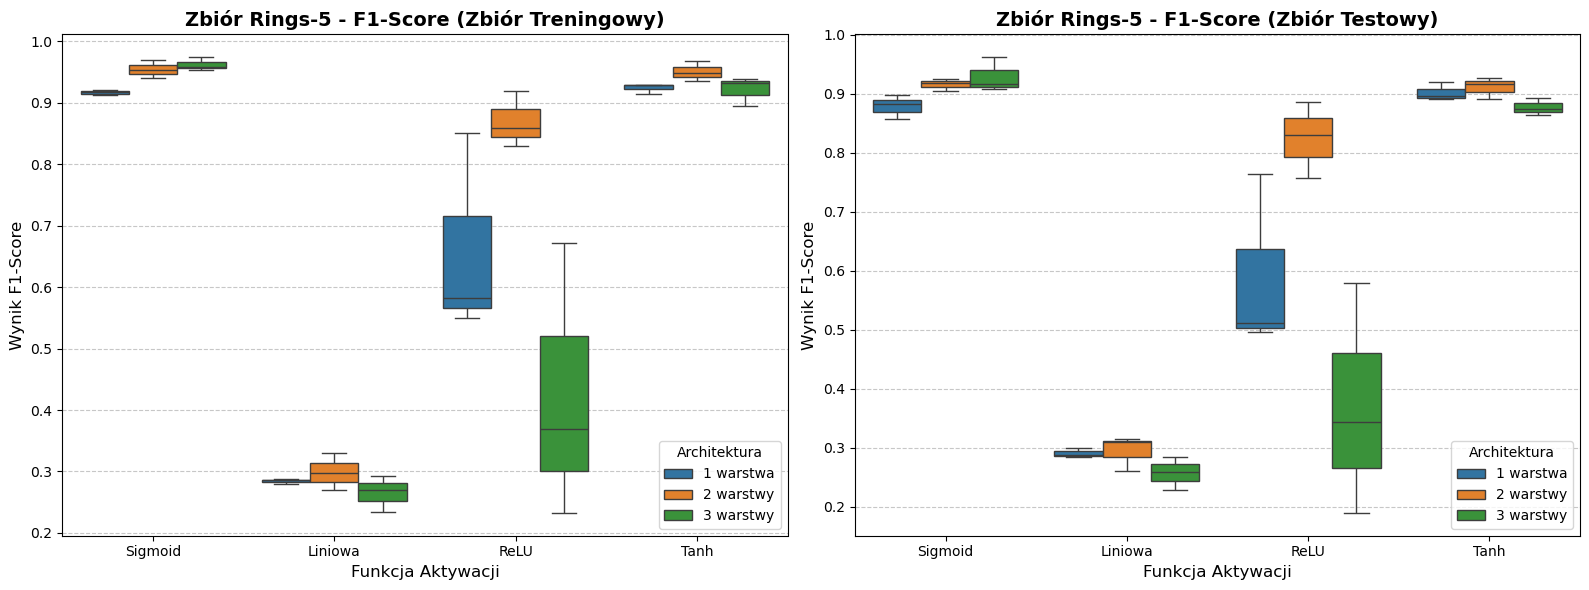

In [30]:
rysuj_boxploty_architektury(df_wyniki, nazwa_zbioru="Zbiór Rings-5", metryka="F1-Score")

# Dane rings3-regular

In [31]:
rings3_regular_test = pd.read_csv("mio1/classification/rings3-regular-test.csv")
rings3_regular_train = pd.read_csv("mio1/classification/rings3-regular-training.csv")

X_train = rings3_regular_train[['x', 'y']].to_numpy() 
y_train_etykiety = rings3_regular_train[['c']].to_numpy().astype(int) 
X_test = rings3_regular_test[['x', 'y']].to_numpy()
y_test_etykiety = rings3_regular_test[['c']].to_numpy().astype(int)

liczba_klas = len(np.unique(y_train_etykiety))
y_train = to_one_hot(y_train_etykiety, liczba_klas)
y_test = to_one_hot(y_test_etykiety, liczba_klas)

In [32]:
df_wyniki = train_N_architektury(X_train, y_train, X_test, y_test, 
                                       N=3, epoki=2000, rozmiar_batcha=64, regresja=False)


Rozpoczynam cykl: Sigmoid + 1 warstwa
F1 testowe FINALNE: 0.9393
F1 testowe FINALNE: 0.9440
F1 testowe FINALNE: 0.9468

Rozpoczynam cykl: Sigmoid + 2 warstwy
F1 testowe FINALNE: 0.9619
F1 testowe FINALNE: 0.9565
F1 testowe FINALNE: 0.9514

Rozpoczynam cykl: Sigmoid + 3 warstwy
F1 testowe FINALNE: 0.9311
F1 testowe FINALNE: 0.9507
F1 testowe FINALNE: 0.9527

Rozpoczynam cykl: Liniowa + 1 warstwa
F1 testowe FINALNE: 0.3684
F1 testowe FINALNE: 0.4489
F1 testowe FINALNE: 0.4277

Rozpoczynam cykl: Liniowa + 2 warstwy
F1 testowe FINALNE: 0.3546
F1 testowe FINALNE: 0.4775
F1 testowe FINALNE: 0.3600

Rozpoczynam cykl: Liniowa + 3 warstwy
F1 testowe FINALNE: 0.3329
F1 testowe FINALNE: 0.3302
F1 testowe FINALNE: 0.4143

Rozpoczynam cykl: ReLU + 1 warstwa
F1 testowe FINALNE: 0.8796
F1 testowe FINALNE: 0.8531
F1 testowe FINALNE: 0.7626

Rozpoczynam cykl: ReLU + 2 warstwy
F1 testowe FINALNE: 0.9329
F1 testowe FINALNE: 0.9372
F1 testowe FINALNE: 0.9416

Rozpoczynam cykl: ReLU + 3 warstwy
F1 testowe

,Aktywacja,Architektura,Score_Trening,Score_Test
0,Sigmoid,1 warstwa,0.946163,0.939320
1,Sigmoid,1 warstwa,0.957335,0.943951
2,Sigmoid,1 warstwa,0.956119,0.946849
3,Sigmoid,2 warstwy,0.978006,0.961933
4,Sigmoid,2 warstwy,0.972040,0.956470
5,Sigmoid,2 warstwy,0.980032,0.951410
6,Sigmoid,3 warstwy,0.953297,0.931079
7,Sigmoid,3 warstwy,0.974659,0.950688
8,Sigmoid,3 warstwy,0.980011,0.952669
9,Liniowa,1 warstwa,0.390573,0.368354


In [33]:
tabela_podsumowujaca(df_wyniki)

=== ZBIÓR TRENINGOWY ===


Architektura 1 warstwa        2 warstwy        3 warstwy       
                  mean    std      mean    std      mean    std
Aktywacja                                                      
Liniowa          0.429  0.035     0.403  0.059     0.372  0.050
ReLU             0.847  0.066     0.960  0.007     0.836  0.146
Sigmoid          0.953  0.006     0.977  0.004     0.969  0.014
Tanh             0.949  0.006     0.956  0.033     0.956  0.005


=== ZBIÓR TESTOWY ===


Architektura 1 warstwa        2 warstwy        3 warstwy       
                  mean    std      mean    std      mean    std
Aktywacja                                                      
Liniowa          0.415  0.042     0.397  0.069     0.359  0.048
ReLU             0.832  0.061     0.937  0.004     0.824  0.114
Sigmoid          0.943  0.004     0.957  0.005     0.945  0.012
Tanh             0.937  0.007     0.935  0.030     0.938  0.004

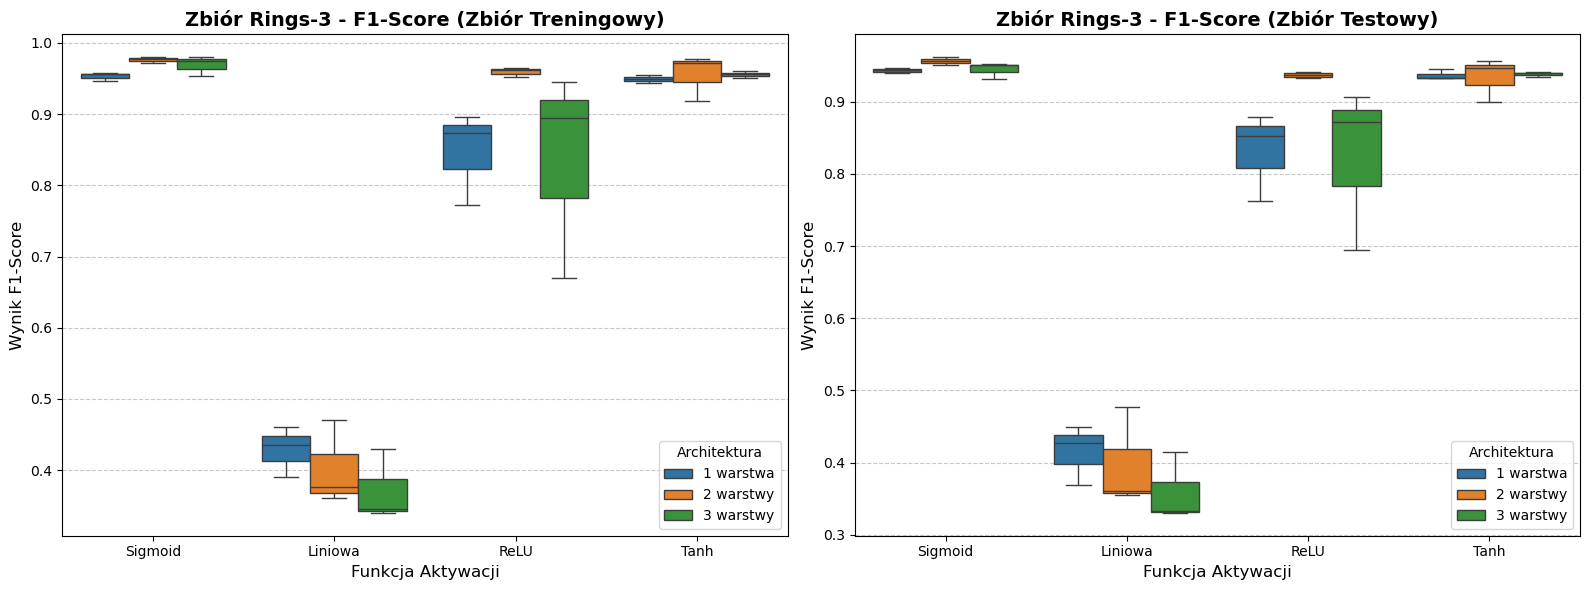

In [34]:
rysuj_boxploty_architektury(df_wyniki, nazwa_zbioru="Zbiór Rings-3", metryka="F1-Score")